In [15]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt

In [16]:
class MNIST_Logistic_Regression(nn.Module):
    def __init__(self):
        super().__init__()
        self.lin = nn.Linear(28*28, 10)

    def forward(self, x):
        return self.lin(x)

In [17]:
mnist_train = datasets.MNIST(
    root='./datasets',
    train=True,
    transform=transforms.ToTensor(),
    download=True)

In [18]:
mnist_test = datasets.MNIST(
    root='./datasets',
    train=False,
    transform=transforms.ToTensor(),
    download=True
)

In [19]:
train_loader = torch.utils.data.DataLoader(
    dataset=mnist_train,
    batch_size=100,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    dataset=mnist_test,
    batch_size=100,
    shuffle=False
)

In [20]:
model = MNIST_Logistic_Regression().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

In [21]:
model.train()
for images, labels in tqdm(train_loader, desc="Обучение"):
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()
    x = images.view(-1, 28 * 28)
    y = model(x)
    loss = criterion(y, labels)

    loss.backward()
    optimizer.step()

print(f"Последний Loss: {loss.item():.4f}")

Обучение: 100%|██████████| 600/600 [00:06<00:00, 97.61it/s] 

Последний Loss: 0.3010


In [22]:
model.eval()
correct = 0
total = len(mnist_test)
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Тестирование"):
        images = images.to(device)
        labels = labels.to(device)
        x = images.view(-1, 28 * 28)
        y = model(x)
        pred = torch.argmax(y, dim=1)
        correct += (pred == labels).sum().item()

print(f"Accuracy: {correct / total:.2%} ({correct}/{total})")

Тестирование: 100%|██████████| 100/100 [00:01<00:00, 94.94it/s]

Accuracy: 90.11% (9011/10000)


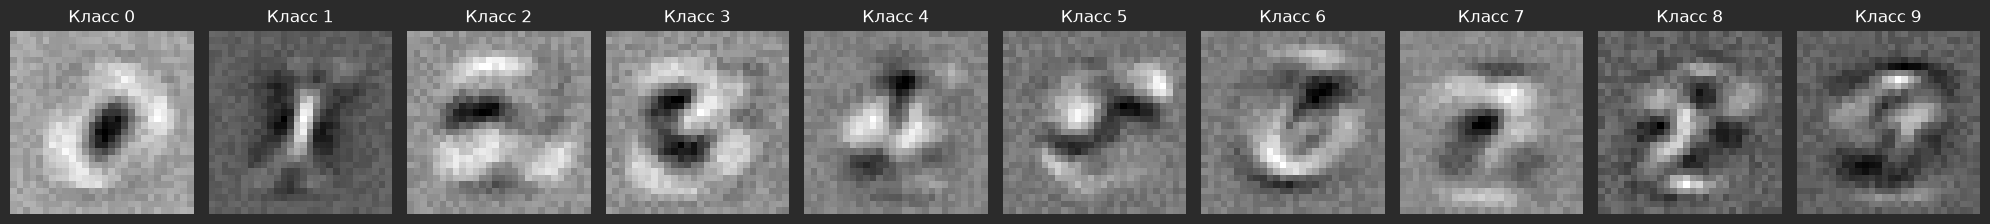

In [23]:
W = model.lin.weight.detach().cpu()
fig, ax = plt.subplots(1, 10, figsize=(20, 5))
for i in range(10):
    ax[i].imshow(W[i].view(28, 28), cmap="gray")
    ax[i].set_title(f"Класс {i}")
    ax[i].axis("off")
plt.tight_layout()
plt.show()